## 1. Thư viện và cấu hình

SentencePiece học subword riêng cho mỗi ngôn ngữ, chỉ từ phần train. Tiếng Việt giữ nguyên dấu và chữ hoa/thường.

Dùng TensorFlow 2.16+; không cần `tensorflow-text`. File RAR được giải nén bằng UnRAR/7-Zip. Colab/Linux cài công cụ giải nén nếu thiếu; Windows tìm UnRAR/7-Zip hoặc dùng thư mục SGML đã giải nén.


In [ ]:
import importlib.util
import importlib.metadata
import subprocess
import sys

requirements = {
    "tensorflow": "tensorflow>=2.16,<2.22",
    "sentencepiece": "sentencepiece>=0.2,<0.3",
    "sacrebleu": "sacrebleu>=2.4,<3",
    "sacremoses": "sacremoses>=0.1,<0.2",
    "requests": "requests>=2.31,<3",
    "pandas": "pandas>=2,<3",
    "matplotlib": "matplotlib>=3.8,<4",
    "rarfile": "rarfile>=4,<5",
    "IPython": "ipython>=8,<10",
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import hashlib
import html
import json
import math
import os
import platform
import random
import re
import shutil
import time
import unicodedata
from datetime import datetime
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rarfile
import requests
import sacrebleu
import sentencepiece as spm
import tensorflow as tf
from IPython.display import Markdown, display
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

SEED = 42
tf.keras.utils.set_random_seed(SEED)
QUICK_RUN = True
DIRECTION = "en_to_vi"
assert DIRECTION in {"en_to_vi", "vi_to_en"}

CFG = dict(
    seed=SEED, quick_run=QUICK_RUN, direction=DIRECTION,
    train_rows=6_000 if QUICK_RUN else None,
    validation_rows=400 if QUICK_RUN else None,
    test_rows=300 if QUICK_RUN else None,
    epochs=12 if QUICK_RUN else 40,
    batch_size=32 if QUICK_RUN else 64,
    vocab_size=4_000 if QUICK_RUN else 8_000,
    max_source_tokens=80 if QUICK_RUN else 128,
    max_target_tokens=80 if QUICK_RUN else 128,
    d_model=96 if QUICK_RUN else 256,
    num_heads=4 if QUICK_RUN else 8,
    num_layers=2 if QUICK_RUN else 4,
    d_ff=256 if QUICK_RUN else 1_024,
    dropout=0.1, peak_lr=0.001, warmup_steps=200 if QUICK_RUN else 1_000,
)
assert CFG["d_model"] % CFG["num_heads"] == 0
assert CFG["d_model"] % 2 == 0

ROOT = Path.cwd()
DATA_DIR = ROOT / "evb_transformer_data"
EXTRACT_DIR = DATA_DIR / "extracted"
# Nếu đã giải nén ở nơi khác, thay đường dẫn này.
LOCAL_SGML_DIR = EXTRACT_DIR
run_key = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:10]
OUTPUT_DIR = ROOT / "evb_transformer_outputs" / f"{DIRECTION}_{run_key}"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
print("Outputs:", OUTPUT_DIR)
display(pd.DataFrame([CFG]).T.rename(columns={0: "value"}))


TensorFlow: 2.21.0


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Outputs: D:\Sudo code 2026\evb_transformer_outputs\en_to_vi_30a44431fc


,value
seed,42
quick_run,True
direction,en_to_vi
train_rows,6000
validation_rows,400
test_rows,300
epochs,12
batch_size,32
vocab_size,4000
max_source_tokens,80


## 2. Tải EVBNews v1.0 và đọc SGML

[Repository EVBCorpus](https://github.com/qhungngo/EVBCorpus) mô tả corpus nhiều lĩnh vực. Notebook dùng **file EVBNews v1.0 công khai**, gồm 1.000 tài liệu tin tức song ngữ; đây là một phần của EVBCorpus.

Đã kiểm tra archive thật: mỗi tài liệu là một file `Nxxxx.sgml`. Trong một `<spair>`, câu `<s id='en...'>` đi cùng câu `<s id='vn...'>`.

Tải từ commit cố định và kiểm tra SHA-256 để tái lập thí nghiệm. Khi mạng lỗi, notebook retry hoặc dùng archive/thư mục SGML local. Không cần Hugging Face Dataset Viewer API.

SGML chứa dấu câu tách bằng khoảng trắng. Giữ quy ước corpus khi train; trước khi chấm điểm, dùng MosesDetokenizer để nối lại dấu câu trong prediction/reference. BLEU sử dụng tokenizer `13a`; protocol được ghi rõ trong báo cáo.


In [ ]:
DATASET_COMMIT = "36bea570ea8e1cdde0f4ce7f4023c03e3b546a73"
ARCHIVE_NAME = "EVBCorpus_EVBNews_v1.0.rar"
ARCHIVE_SHA256 = "50bb92616c6ee32046a71ec6041c264d9d0f60a662e5c55257f3092c012301c4"
ARCHIVE_URL = (
    f"https://raw.githubusercontent.com/qhungngo/EVBCorpus/"
    f"{DATASET_COMMIT}/{ARCHIVE_NAME}"
)
ARCHIVE_PATH = DATA_DIR / ARCHIVE_NAME

def file_sha256(path):
    hasher = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

def ensure_archive():
    if ARCHIVE_PATH.exists():
        if file_sha256(ARCHIVE_PATH) != ARCHIVE_SHA256:
            raise ValueError(
                "Archive local có SHA-256 khác bản đã kiểm tra. "
                "Đổi tên file này rồi tải lại, hoặc kiểm tra nguồn của bạn."
            )
        return
    retry = Retry(total=5, backoff_factor=1,
                  status_forcelist=[429, 500, 502, 503, 504])
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    part_path = ARCHIVE_PATH.with_suffix(".rar.part")
    print("Downloading:", ARCHIVE_URL)
    with session.get(ARCHIVE_URL, stream=True, timeout=(15, 90)) as response:
        response.raise_for_status()
        with open(part_path, "wb") as stream:
            for chunk in response.iter_content(1024 * 1024):
                stream.write(chunk)
    if file_sha256(part_path) != ARCHIVE_SHA256:
        raise ValueError("Download thiếu hoặc sai checksum; hãy chạy lại cell.")
    part_path.replace(ARCHIVE_PATH)

def ensure_sgml_files():
    existing = sorted(LOCAL_SGML_DIR.rglob("*.sgml")) if LOCAL_SGML_DIR.exists() else []
    if len(existing) == 1_000:
        return existing
    if LOCAL_SGML_DIR != EXTRACT_DIR:
        raise ValueError("LOCAL_SGML_DIR cần chứa đủ 1.000 file SGML của EVBNews v1.0.")
    ensure_archive()
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    candidates = [
        shutil.which("unrar"), shutil.which("unar"), shutil.which("7z"),
        shutil.which("7zz"), shutil.which("bsdtar"),
        r"C:\Program Files\WinRAR\UnRAR.exe",
        r"C:\Program Files\7-Zip\7z.exe",
    ]
    backend = next((path for path in candidates if path and Path(path).is_file()), None)
    if backend is None and platform.system() == "Linux":
        subprocess.check_call(["apt-get", "-qq", "update"])
        subprocess.check_call(["apt-get", "-qq", "install", "-y", "unrar-free"])
        backend = shutil.which("unrar-free") or shutil.which("unrar")
    if backend is None:
        raise RuntimeError(
            "Chưa có công cụ giải nén RAR. Cài UnRAR/7-Zip, "
            "hoặc giải nén thủ công và đặt LOCAL_SGML_DIR."
        )
    # Kiểm tra tên thành viên trước khi giải nén vào thư mục riêng.
    with rarfile.RarFile(ARCHIVE_PATH) as archive:
        root = EXTRACT_DIR.resolve()
        for member in archive.infolist():
            member_name = member.filename.replace("\\", "/")
            resolved = (root / member_name).resolve()
            if not resolved.is_relative_to(root):
                raise ValueError("Archive có đường dẫn ngoài thư mục giải nén.")
    name = Path(backend).name.lower()
    if name.startswith("7z"):
        cmd = [backend, "x", "-y", f"-o{EXTRACT_DIR}", str(ARCHIVE_PATH)]
    elif name == "unar":
        cmd = [backend, "-f", "-o", str(EXTRACT_DIR), str(ARCHIVE_PATH)]
    elif name == "bsdtar":
        cmd = [backend, "-xf", str(ARCHIVE_PATH), "-C", str(EXTRACT_DIR)]
    elif name == "unrar-free":
        cmd = [backend, "-x", str(ARCHIVE_PATH), str(EXTRACT_DIR) + os.sep]
    else:
        cmd = [backend, "x", "-o-", "-idq", str(ARCHIVE_PATH), str(EXTRACT_DIR) + os.sep]
    subprocess.check_call(cmd, stdout=subprocess.DEVNULL)
    files = sorted(EXTRACT_DIR.rglob("*.sgml"))
    if len(files) != 1_000:
        raise RuntimeError(f"Cần 1.000 file SGML, hiện có {len(files)}.")
    return files

def normalize_text(text):
    # Giữ dấu tiếng Việt, tên riêng, số và dấu câu.
    text = html.unescape(text)
    text = unicodedata.normalize("NFC", text)
    return re.sub(r"\s+", " ", text).strip()

def parse_sgml(files):
    rows, malformed = [], []
    total_spairs = 0
    for path in files:
        text = path.read_text(encoding="utf-8-sig")
        doc_match = re.search(r"<doc\b[^>]*\bid=['\"]([^'\"]+)['\"]", text)
        doc_id = doc_match.group(1) if doc_match else path.stem
        for match in re.finditer(
            r"<spair\b[^>]*\bid=['\"]([^'\"]+)['\"][^>]*>(.*?)</spair>",
            text, flags=re.DOTALL | re.IGNORECASE,
        ):
            pair_id, block = match.groups()
            sentences = re.findall(
                r"<s\b[^>]*\bid=['\"]((?:en|vn)[^'\"]*)['\"][^>]*>(.*?)</s>",
                block, flags=re.DOTALL | re.IGNORECASE,
            )
            en = [normalize_text(value) for key, value in sentences
                  if key.lower().startswith("en")]
            vi = [normalize_text(value) for key, value in sentences
                  if key.lower().startswith("vn")]
            total_spairs += 1
            if len(en) != 1 or len(vi) != 1:
                malformed.append({"doc_id": doc_id, "pair_id": pair_id,
                                  "english_count": len(en), "vietnamese_count": len(vi)})
                continue
            rows.append(dict(doc_id=doc_id, pair_id=pair_id, en=en[0], vi=vi[0]))
    return pd.DataFrame(rows), total_spairs, malformed

sgml_files = ensure_sgml_files()
raw_df, total_spairs, malformed = parse_sgml(sgml_files)
assert raw_df["doc_id"].nunique() == 1_000
print(f"Documents: {len(sgml_files):,}; spairs: {total_spairs:,}; parsed: {len(raw_df):,}")
print("Malformed pairs skipped:", len(malformed))
display(raw_df.head(3))
(OUTPUT_DIR / "malformed_pairs.json").write_text(
    json.dumps(malformed, ensure_ascii=False, indent=2), encoding="utf-8"
)


Documents: 1,000; spairs: 45,308; parsed: 45,308
Malformed pairs skipped: 0


,doc_id,pair_id,en,vi
0,N0001,1,What is a Fenqing ?,Fenqing là gì ?
1,N0001,2,Fenqing is a Chinese word which literally mean...,"Fenqing là một từ tiếng Hoa mà nghĩa đen là "" ..."
2,N0001,3,This word has many translations in English suc...,Từ này có nhiều cách dịch sang tiếng Anh như l...


2

## 3. Làm sạch và chia theo tài liệu

Loại câu rỗng/quá dài ở bước sơ bộ, cặp có tỉ lệ độ dài bất thường và câu trùng hoàn toàn. Khóa trùng dùng `casefold()` để bắt cả trường hợp khác chữ hoa/thường.

Chia ngẫu nhiên **80% tài liệu train, 10% validation, 10% test**, seed cố định. Mỗi bài báo chỉ thuộc một tập. Tokenizer học sau bước chia; validation chọn checkpoint, test dùng khi báo cáo cuối.

Đây là split tự tạo, không phải official test set. Chia theo bài báo giảm rò rỉ theo chủ đề nhưng chưa loại hết các bài gần giống nhau.


In [ ]:
en_len = raw_df["en"].str.split().map(len)
vi_len = raw_df["vi"].str.split().map(len)
ratio = en_len / vi_len.clip(lower=1)
keep = (
    en_len.between(2, 100) & vi_len.between(2, 100)
    & ratio.between(0.25, 4)
    & ~raw_df["en"].str.contains("\ufffd", regex=False)
    & ~raw_df["vi"].str.contains("\ufffd", regex=False)
)
clean_df = raw_df.loc[keep].copy()
before_dedup = len(clean_df)
clean_df["_en_key"] = clean_df["en"].str.casefold()
clean_df["_vi_key"] = clean_df["vi"].str.casefold()
clean_df = clean_df.drop_duplicates("_en_key").drop_duplicates("_vi_key")
clean_df = clean_df.drop(columns=["_en_key", "_vi_key"]).reset_index(drop=True)

documents = np.array(sorted(raw_df["doc_id"].unique()))
np.random.default_rng(SEED).shuffle(documents)
n_train_docs = int(0.8 * len(documents))
n_val_docs = int(0.1 * len(documents))
document_splits = {
    "train": documents[:n_train_docs].tolist(),
    "validation": documents[n_train_docs:n_train_docs + n_val_docs].tolist(),
    "test": documents[n_train_docs + n_val_docs:].tolist(),
}
source_column, target_column = ("en", "vi") if DIRECTION == "en_to_vi" else ("vi", "en")
frames = {}
for name, ids in document_splits.items():
    frame = clean_df[clean_df["doc_id"].isin(ids)].copy()
    frame = frame.rename(columns={source_column: "source", target_column: "target"})
    frames[name] = frame.sample(frac=1, random_state=SEED).reset_index(drop=True)

def assert_no_leakage(frames):
    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
        assert not set(frames[left]["doc_id"]) & set(frames[right]["doc_id"])
        for column in ["source", "target"]:
            assert not (set(frames[left][column].str.casefold())
                        & set(frames[right][column].str.casefold()))

assert_no_leakage(frames)
train_candidate = frames["train"]
if CFG["train_rows"] is not None:
    train_candidate = train_candidate.head(CFG["train_rows"]).copy()

cleaning_stats = dict(
    archive_files=len(sgml_files), raw_spairs=total_spairs,
    parsed_pairs=len(raw_df), malformed_pairs=len(malformed),
    basic_filtered_pairs=len(raw_df) - int(keep.sum()),
    duplicate_pairs=before_dedup - len(clean_df),
    clean_pairs=len(clean_df),
)
print("Cleaning:", cleaning_stats)
display(pd.DataFrame([
    {"split": name, "documents": len(document_splits[name]), "pairs_before_subword_filter": len(frame)}
    for name, frame in frames.items()
]))
(OUTPUT_DIR / "document_splits.json").write_text(
    json.dumps(document_splits, indent=2), encoding="utf-8"
)


Cleaning: {'archive_files': 1000, 'raw_spairs': 45308, 'parsed_pairs': 45308, 'malformed_pairs': 0, 'basic_filtered_pairs': 416, 'duplicate_pairs': 2421, 'clean_pairs': 42471}


,split,documents,pairs_before_subword_filter
0,train,800,34493
1,validation,100,3905
2,test,100,4073


13057

## 4. Subword tokenizer và teacher forcing

**Subword** chia từ thành các phần nhỏ, giúp xử lý từ ít gặp mà không cần vocabulary rất lớn. Không cần bỏ dấu hoặc word segmentation riêng cho tiếng Việt trong bài này.

Quy ước ID: `PAD=0, UNK=1, BOS=2, EOS=3`. Tokenizer học từ `train_candidate` và được lưu cùng model.

Sau tokenization, loại cặp vượt giới hạn ở cả train/validation/test. **Không cắt reference**; báo cáo chỉ áp dụng cho tập câu trong giới hạn của cấu hình.

Teacher forcing dịch target lệch một token:

```text
Target:        BOS  tôi   thích  học  EOS
Decoder input: BOS  tôi   thích  học
Label:         tôi  thích học    EOS
```

Khi suy luận, decoder tự dùng token đã sinh và không nhận reference.


In [ ]:
def train_tokenizer(texts, prefix):
    spm.SentencePieceTrainer.train(
        sentence_iterator=iter(texts),
        model_prefix=str(prefix), model_type="bpe",
        vocab_size=CFG["vocab_size"], character_coverage=1.0,
        pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        normalization_rule_name="identity",
        hard_vocab_limit=False, shuffle_input_sentence=False,
        num_threads=1, minloglevel=2,
    )
    return spm.SentencePieceProcessor(model_file=str(prefix) + ".model")

source_sp = train_tokenizer(train_candidate["source"].tolist(), OUTPUT_DIR / "source_sp")
target_sp = train_tokenizer(train_candidate["target"].tolist(), OUTPUT_DIR / "target_sp")
for tokenizer in [source_sp, target_sp]:
    assert [tokenizer.pad_id(), tokenizer.unk_id(), tokenizer.bos_id(), tokenizer.eos_id()] == [PAD, UNK, BOS, EOS]
CFG["source_vocab_size"] = source_sp.get_piece_size()
CFG["target_vocab_size"] = target_sp.get_piece_size()

def encode_frame(frame):
    result = frame.copy()
    result["source_ids"] = source_sp.encode(result["source"].tolist(), out_type=int,
                                          add_bos=True, add_eos=True)
    result["target_ids"] = target_sp.encode(result["target"].tolist(), out_type=int,
                                          add_bos=True, add_eos=True)
    valid = (
        result["source_ids"].map(len).le(CFG["max_source_tokens"])
        & result["target_ids"].map(len).le(CFG["max_target_tokens"])
    )
    return result.loc[valid].reset_index(drop=True), int((~valid).sum())

selected, length_drops = {}, {}
for name in frames:
    candidate = train_candidate if name == "train" else frames[name]
    encoded, dropped = encode_frame(candidate)
    cap = CFG[f"{name}_rows"]
    selected[name] = encoded.head(cap).copy() if cap is not None else encoded
    length_drops[name] = dict(candidate_pairs=len(candidate), dropped_too_long=dropped,
                              eligible_pairs=len(encoded), selected_pairs=len(selected[name]))
    if len(selected[name]) < 20:
        raise ValueError(f"Tập {name} quá nhỏ. Tăng train_rows hoặc giới hạn token.")

train_df, val_df, test_df = [selected[name] for name in ["train", "validation", "test"]]
assert_no_leakage(selected)
for name, frame in selected.items():
    frame[["doc_id", "pair_id", "source", "target"]].to_json(
        OUTPUT_DIR / f"{name}_pairs.jsonl", orient="records", lines=True, force_ascii=False
    )
display(pd.DataFrame(length_drops).T)
print("Actual vocabulary:", CFG["source_vocab_size"], CFG["target_vocab_size"])
example = train_df.iloc[0]
print("Source:", example["source"])
print("Source pieces:", source_sp.encode(example["source"], out_type=str))
print("Target pieces:", target_sp.encode(example["target"], out_type=str))

def make_dataset(frame, training=False):
    source = tf.keras.utils.pad_sequences(
        frame["source_ids"], maxlen=CFG["max_source_tokens"],
        padding="post", truncating="post", value=PAD, dtype="int32"
    )
    target = tf.keras.utils.pad_sequences(
        frame["target_ids"], maxlen=CFG["max_target_tokens"],
        padding="post", truncating="post", value=PAD, dtype="int32"
    )
    ds = tf.data.Dataset.from_tensor_slices(((source, target[:, :-1]), target[:, 1:]))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    # Giảm lượng PAD phải tính trong mỗi batch.
    def trim_batch(inputs, labels):
        src, tgt = inputs
        src_len = tf.reduce_max(tf.reduce_sum(tf.cast(src != PAD, tf.int32), axis=1))
        tgt_len = tf.reduce_max(tf.reduce_sum(tf.cast(labels != PAD, tf.int32), axis=1))
        return (src[:, :src_len], tgt[:, :tgt_len]), labels[:, :tgt_len]
    return (ds.batch(CFG["batch_size"])
            .map(trim_batch, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
batch_inputs, batch_labels = next(iter(train_ds))
print("Source, decoder input, labels:", batch_inputs[0].shape, batch_inputs[1].shape, batch_labels.shape)


,candidate_pairs,dropped_too_long,eligible_pairs,selected_pairs
train,6000,82,5918,5918
validation,3905,66,3839,400
test,4073,55,4018,300


Actual vocabulary: 4000 4000
Source: Many people who have written on the subject of allowances say it is not a good idea to pay your child for work around the home .
Source pieces: ['▁Many', '▁people', '▁who', '▁have', '▁written', '▁on', '▁the', '▁subject', '▁of', '▁allow', 'ances', '▁say', '▁it', '▁is', '▁not', '▁a', '▁good', '▁idea', '▁to', '▁pay', '▁your', '▁child', '▁for', '▁work', '▁around', '▁the', '▁home', '▁.']
Target pieces: ['▁Những', '▁người', '▁có', '▁những', '▁bài', '▁viết', '▁về', '▁đề', '▁tài', '▁tiền', '▁phụ', '▁cấp', '▁cho', '▁rằng', '▁việc', '▁trả', '▁công', '▁cho', '▁con', '▁cái', '▁khi', '▁chúng', '▁làm', '▁việc', '▁nhà', '▁không', '▁phải', '▁là', '▁một', '▁ý', '▁tưởng', '▁hay', '▁.']


Source, decoder input, labels: (32, 74) (32, 68) (32, 68)


## 5. Xây dựng Transformer

Kiến trúc gồm:

- **Embedding + sinusoidal positional encoding** biểu diễn token và vị trí.
- **Encoder self-attention**: mỗi token nguồn nhìn các token nguồn khác.
- **Decoder causal self-attention**: chỉ nhìn token đích hiện tại và quá khứ.
- **Cross-attention**: decoder dùng câu nguồn để dự đoán token tiếp theo.
- **Feed-forward, residual connection, layer normalization, dropout**.
- **Dense output** trả logits của vocabulary đích.

Scaled dot-product attention tính `softmax(QKᵀ / sqrt(d_k))V`. Keras `MultiHeadAttention` thực hiện bước này. `key_dim = d_model / num_heads` là chiều của **mỗi head**.

Padding mask chặn key PAD; causal mask chặn token đích tương lai. Vị trí PAD cũng được loại khỏi loss và accuracy.


In [ ]:
class PositionalEmbedding(tf.keras.layers.Layer):
    def __init__(self, vocab_size, d_model, max_length, **kwargs):
        super().__init__(**kwargs)
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model)
        self.scale = math.sqrt(d_model)
        positions = np.arange(max_length)[:, None]
        frequencies = np.exp(np.arange(0, d_model, 2) * (-math.log(10_000.0) / d_model))
        encoding = np.zeros((max_length, d_model), dtype=np.float32)
        encoding[:, 0::2] = np.sin(positions * frequencies)
        encoding[:, 1::2] = np.cos(positions * frequencies)
        self.positions = tf.constant(encoding)

    def call(self, tokens):
        x = self.embedding(tokens) * self.scale
        return x + self.positions[None, :tf.shape(tokens)[1], :]

class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, cfg, **kwargs):
        super().__init__(**kwargs)
        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=cfg["num_heads"], key_dim=cfg["d_model"] // cfg["num_heads"],
            dropout=cfg["dropout"],
        )
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(cfg["d_ff"], activation="relu"),
            tf.keras.layers.Dense(cfg["d_model"]),
        ])
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = tf.keras.layers.Dropout(cfg["dropout"])
        self.drop2 = tf.keras.layers.Dropout(cfg["dropout"])

    def call(self, x, valid, training=False):
        attended = self.attention(query=x, value=x,
                                  attention_mask=valid[:, None, :], training=training)
        x = self.norm1(x + self.drop1(attended, training=training))
        x = self.norm2(x + self.drop2(self.ffn(x), training=training))
        return x * tf.cast(valid[:, :, None], x.dtype)

class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, cfg, **kwargs):
        super().__init__(**kwargs)
        attention_args = dict(num_heads=cfg["num_heads"],
                              key_dim=cfg["d_model"] // cfg["num_heads"],
                              dropout=cfg["dropout"])
        self.self_attention = tf.keras.layers.MultiHeadAttention(**attention_args)
        self.cross_attention = tf.keras.layers.MultiHeadAttention(**attention_args)
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(cfg["d_ff"], activation="relu"),
            tf.keras.layers.Dense(cfg["d_model"]),
        ])
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm3 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = tf.keras.layers.Dropout(cfg["dropout"])
        self.drop2 = tf.keras.layers.Dropout(cfg["dropout"])
        self.drop3 = tf.keras.layers.Dropout(cfg["dropout"])
        self.last_attention_scores = None

    def call(self, x, context, target_valid, source_valid, training=False):
        attended = self.self_attention(
            query=x, value=x, attention_mask=target_valid[:, None, :],
            use_causal_mask=True, training=training,
        )
        x = self.norm1(x + self.drop1(attended, training=training))
        attended, scores = self.cross_attention(
            query=x, value=context, attention_mask=source_valid[:, None, :],
            return_attention_scores=True, training=training,
        )
        self.last_attention_scores = scores
        x = self.norm2(x + self.drop2(attended, training=training))
        x = self.norm3(x + self.drop3(self.ffn(x), training=training))
        return x * tf.cast(target_valid[:, :, None], x.dtype)

class Transformer(tf.keras.Model):
    def __init__(self, cfg, **kwargs):
        super().__init__(**kwargs)
        self.source_embedding = PositionalEmbedding(
            cfg["source_vocab_size"], cfg["d_model"], cfg["max_source_tokens"]
        )
        self.target_embedding = PositionalEmbedding(
            cfg["target_vocab_size"], cfg["d_model"], cfg["max_target_tokens"]
        )
        self.encoder_blocks = [EncoderBlock(cfg) for _ in range(cfg["num_layers"])]
        self.decoder_blocks = [DecoderBlock(cfg) for _ in range(cfg["num_layers"])]
        self.encoder_dropout = tf.keras.layers.Dropout(cfg["dropout"])
        self.decoder_dropout = tf.keras.layers.Dropout(cfg["dropout"])
        self.projection = tf.keras.layers.Dense(cfg["target_vocab_size"])

    def encode(self, source_tokens, training=False):
        valid = source_tokens != PAD
        x = self.encoder_dropout(self.source_embedding(source_tokens), training=training)
        for block in self.encoder_blocks:
            x = block(x, valid, training=training)
        return x, valid

    def decode(self, target_tokens, context, source_valid, training=False):
        valid = target_tokens != PAD
        x = self.decoder_dropout(self.target_embedding(target_tokens), training=training)
        for block in self.decoder_blocks:
            x = block(x, context, valid, source_valid, training=training)
        return self.projection(x)

    def call(self, inputs, training=False):
        source_tokens, target_tokens = inputs
        context, source_valid = self.encode(source_tokens, training=training)
        return self.decode(target_tokens, context, source_valid, training=training)

model = Transformer(CFG, name="evb_transformer")
logits = model(batch_inputs, training=False)
assert logits.shape[:2] == batch_labels.shape
assert logits.shape[-1] == CFG["target_vocab_size"]
model.summary()


Model: "evb_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ positional_embedding            │ ?                      │       384,000 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_embedding_1          │ ?                      │       384,000 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block (EncoderBlock)    │ ?                      │        87,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_1 (EncoderBlock)  │ ?                      │        87,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block (DecoderBlock)    │ ?                      │       124,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_1 (DecoderBlock)  │ ?                      │       124,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (32, 68, 4000)         │       388,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,579,424 (6.03 MB)

 Trainable params: 1,579,424 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Loss, learning rate và kiểm tra masking

Loss là cross-entropy trung bình trên token không phải PAD. Accuracy bỏ PAD và tích lũy số token qua các batch.

Learning rate tăng dần trong warmup rồi giảm theo căn bậc hai của số bước. Cấu hình nhỏ dùng đỉnh learning rate riêng; đây là lịch điều chỉnh cho bài học, không phải cấu hình Transformer-base trong paper.

Trước khi train, kiểm tra: đổi token tương lai không thay đổi logits quá khứ; thêm PAD vào nguồn không đổi dự đoán; thay logits ở label PAD không đổi loss.


In [ ]:
token_loss = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction="none"
)

def masked_loss(labels, logits):
    mask = tf.cast(labels != PAD, tf.float32)
    values = token_loss(labels, logits) * mask
    return tf.math.divide_no_nan(tf.reduce_sum(values), tf.reduce_sum(mask))

class MaskedTokenAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="masked_token_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.total = self.add_weight(name="total", initializer="zeros")

    def update_state(self, labels, logits, sample_weight=None):
        predictions = tf.argmax(logits, axis=-1, output_type=labels.dtype)
        mask = tf.cast(labels != PAD, tf.float32)
        correct = tf.cast(labels == predictions, tf.float32) * mask
        self.correct.assign_add(tf.reduce_sum(correct))
        self.total.assign_add(tf.reduce_sum(mask))

    def result(self):
        return tf.math.divide_no_nan(self.correct, self.total)

    def reset_state(self):
        self.correct.assign(0.0)
        self.total.assign(0.0)

class WarmupSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak_lr, warmup_steps):
        super().__init__()
        self.peak_lr = peak_lr
        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step + 1, tf.float32)
        warmup = tf.cast(self.warmup_steps, tf.float32)
        return self.peak_lr * tf.minimum(step / warmup, tf.sqrt(warmup / step))

    def get_config(self):
        return dict(peak_lr=self.peak_lr, warmup_steps=self.warmup_steps)

check_source = tf.constant([[BOS, 5, 6, EOS]], tf.int32)
target_a = tf.constant([[BOS, 5, 6]], tf.int32)
target_b = tf.constant([[BOS, 5, 7]], tf.int32)
a = model((check_source, target_a), training=False)
b = model((check_source, target_b), training=False)
np.testing.assert_allclose(a.numpy()[:, :2], b.numpy()[:, :2], atol=2e-5, rtol=2e-5)
source_with_pad = tf.pad(check_source, [[0, 0], [0, 2]])
c = model((source_with_pad, target_a), training=False)
np.testing.assert_allclose(a.numpy(), c.numpy(), atol=2e-5, rtol=2e-5)
check_labels = tf.constant([[5, EOS, PAD]], tf.int32)
changed = tf.concat([a[:, :2], tf.zeros_like(a[:, 2:]) + 100.0], axis=1)
np.testing.assert_allclose(masked_loss(check_labels, a), masked_loss(check_labels, changed))
print("Mask checks passed; initial loss:", float(masked_loss(batch_labels, logits)))

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=WarmupSchedule(CFG["peak_lr"], CFG["warmup_steps"]),
        beta_1=0.9, beta_2=0.98, epsilon=1e-9, clipnorm=1.0,
    ),
    loss=masked_loss, metrics=[MaskedTokenAccuracy()],
)


Mask checks passed; initial loss: 8.306159019470215


## 7. Huấn luyện và lưu checkpoint

Theo dõi train/validation loss từng epoch. Lưu checkpoint có **validation loss thấp nhất** để đánh giá test. Early stopping dừng khi validation loss không cải thiện.

`masked_token_accuracy` trong training dùng teacher forcing: dự đoán token khi có prefix đúng. Nó **không phải BLEU hay tỉ lệ câu dịch đúng**.

Thời gian train phụ thuộc CPU/GPU. Giảm `train_rows`, `epochs` hoặc `num_layers` trong cấu hình để kiểm tra nhanh hơn; thay cấu hình tạo thư mục kết quả riêng.


Epoch 1/12


  Epoch 1: 39.2s
185/185 - 39s - 212ms/step - loss: 7.2705 - masked_token_accuracy: 0.0492 - val_loss: 6.4751 - val_masked_token_accuracy: 0.0819


Epoch 2/12


  Epoch 2: 25.2s
185/185 - 25s - 136ms/step - loss: 5.9282 - masked_token_accuracy: 0.1362 - val_loss: 5.5619 - val_masked_token_accuracy: 0.1691


Epoch 3/12


...

  Epoch 11: 39.5s
185/185 - 40s - 214ms/step - loss: 3.7740 - masked_token_accuracy: 0.3162 - val_loss: 4.6875 - val_masked_token_accuracy: 0.2490


Epoch 12/12


  Epoch 12: 43.9s
185/185 - 44s - 237ms/step - loss: 3.6849 - masked_token_accuracy: 0.3256 - val_loss: 4.6665 - val_masked_token_accuracy: 0.2526


Best epoch: 12 Training minutes: 6.8


,epoch,epoch_seconds,loss,masked_token_accuracy,val_loss,val_masked_token_accuracy
7,8,31.576203,4.093451,0.286857,4.751478,0.240613
8,9,31.854837,3.973801,0.296930,4.718206,0.243495
9,10,36.810889,3.870635,0.307796,4.703509,0.245306
10,11,39.500305,3.774040,0.316232,4.687455,0.249012
11,12,43.872594,3.684890,0.325571,4.666495,0.252553


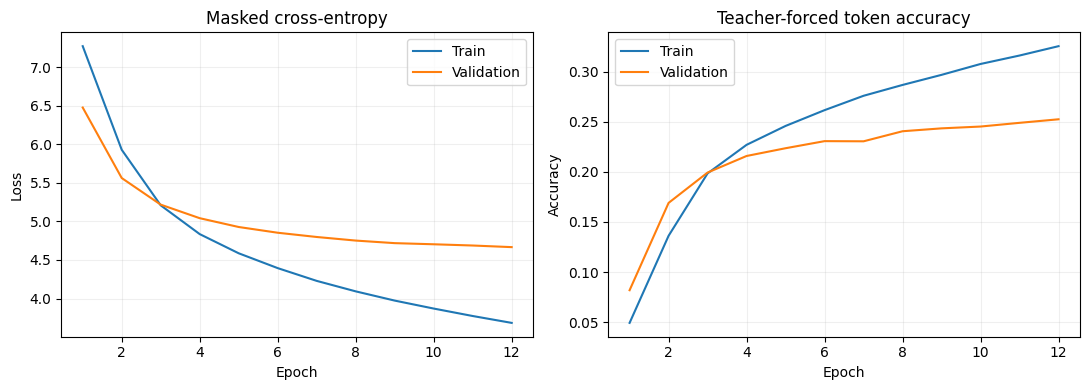

In [ ]:
class EpochTimer(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []

    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        seconds = time.perf_counter() - self.started
        row = dict(epoch=epoch + 1, epoch_seconds=seconds, **(logs or {}))
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
        print(f"  Epoch {epoch + 1}: {seconds:.1f}s")

BEST_WEIGHTS = OUTPUT_DIR / "best_transformer.weights.h5"
timer = EpochTimer()
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_WEIGHTS), monitor="val_loss", mode="min",
        save_best_only=True, save_weights_only=True,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, mode="min", restore_best_weights=True,
    ),
    tf.keras.callbacks.TerminateOnNaN(),
    timer,
]
training_started = time.perf_counter()
history = model.fit(
    train_ds, validation_data=val_ds, epochs=CFG["epochs"],
    callbacks=callbacks, verbose=2,
)
training_seconds = time.perf_counter() - training_started
model.load_weights(BEST_WEIGHTS)
history_df = pd.DataFrame(timer.rows)
best_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])
print("Best epoch:", best_epoch, "Training minutes:", round(training_seconds / 60, 2))
display(history_df.tail())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["epoch"], history_df["loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set(title="Masked cross-entropy", xlabel="Epoch", ylabel="Loss")
axes[1].plot(history_df["epoch"], history_df["masked_token_accuracy"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_masked_token_accuracy"], label="Validation")
axes[1].set(title="Teacher-forced token accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()


## 8. Sinh bản dịch bằng greedy decoding

Bắt đầu bằng BOS, lấy token xác suất cao nhất, nối vào prefix và lặp đến EOS hoặc giới hạn độ dài. Encoder chỉ chạy một lần cho mỗi batch.

Hàm dịch **chỉ nhận câu nguồn**. Reference không được dùng khi sinh bản dịch. Câu nguồn vượt giới hạn sẽ báo lỗi, để bạn chia câu ngắn hoặc train với giới hạn lớn hơn.

Greedy decoding dễ hiểu nhưng có thể kém beam search. Báo cáo ghi rõ phương pháp giải mã.


In [ ]:
from sacremoses import MosesDetokenizer

source_detokenizer = MosesDetokenizer(lang="en" if DIRECTION == "en_to_vi" else "vi")
target_detokenizer = MosesDetokenizer(lang="vi" if DIRECTION == "en_to_vi" else "en")

def make_greedy_decoder(transformer, cfg):
    vocab_size = cfg["target_vocab_size"]
    # Không sinh PAD hoặc BOS ở giữa bản dịch.
    blocked = tf.reduce_sum(tf.one_hot([PAD, BOS], vocab_size, dtype=tf.float32), axis=0)

    @tf.function(input_signature=[tf.TensorSpec([None, None], tf.int32)])
    def generate(source_tokens):
        context, source_valid = transformer.encode(source_tokens, training=False)
        batch_size = tf.shape(source_tokens)[0]
        tokens = tf.fill([batch_size, 1], tf.cast(BOS, tf.int32))
        finished = tf.zeros([batch_size], tf.bool)
        for step in tf.range(cfg["max_target_tokens"] - 1):
            tf.autograph.experimental.set_loop_options(
                shape_invariants=[(tokens, tf.TensorShape([None, None]))]
            )
            logits = transformer.decode(tokens, context, source_valid, training=False)
            next_id = tf.argmax(logits[:, -1, :] - blocked * 1e9,
                                axis=-1, output_type=tf.int32)
            next_id = tf.where(finished, tf.cast(PAD, tf.int32), next_id)
            tokens = tf.concat([tokens, next_id[:, None]], axis=1)
            finished = finished | (next_id == EOS)
            if tf.reduce_all(finished):
                break
        return tokens
    return generate

greedy_decoder = make_greedy_decoder(model, CFG)

def prepare_source_batch(texts, tokenizer=source_sp, cfg=CFG):
    texts = [normalize_text(text) for text in texts]
    encoded = tokenizer.encode(texts, out_type=int, add_bos=True, add_eos=True)
    if any(len(ids) > cfg["max_source_tokens"] for ids in encoded):
        raise ValueError(
            f"Câu nguồn vượt {cfg['max_source_tokens']} subword tokens. "
            "Chia thành câu ngắn hoặc train lại với giới hạn lớn hơn."
        )
    return tf.constant(tf.keras.utils.pad_sequences(
        encoded, padding="post", value=PAD, dtype="int32"
    ))

def decode_target(ids, tokenizer=target_sp):
    ids = list(map(int, ids))
    if EOS in ids:
        ids = ids[:ids.index(EOS)]
    ids = [token for token in ids if token not in {PAD, BOS}]
    return normalize_text(target_detokenizer.detokenize(tokenizer.decode(ids).split()))

def translate_batch(texts, decoder=greedy_decoder, src_tokenizer=source_sp,
                    tgt_tokenizer=target_sp, cfg=CFG):
    if not texts:
        return [], []
    source_tokens = prepare_source_batch(texts, src_tokenizer, cfg)
    generated = decoder(source_tokens).numpy().tolist()
    return [decode_target(ids, tgt_tokenizer) for ids in generated], generated

def translate(text):
    return translate_batch([text])[0][0]

print("Source:", test_df.iloc[0]["source"])
print("Prediction:", translate(test_df.iloc[0]["source"]))


Source: Earlier on Wednesday the maid 's lawyer , Jeffrey Shapiro , said that his client feared for herself and her daughter when she discovered Mr Strauss-Kahn 's identity a day after the incident on 14 May .


Prediction: Trước khi công ty của hãng hàng ngày, giám đốc điều kiện này, một cuộc họp báo cáo của cô ấy nói rằng nó sẽ làm việc với cô ấy và tôi đã nói rằng việc mua sắm của cô ấy vào ngày thứ ba ngày thứ ba ngày sau khi cô ấy.


## 9. Đánh giá translation quality

Dùng checkpoint chọn trên validation, sinh bản dịch tự do cho **toàn bộ test được chọn**, rồi tính corpus-level metrics trên văn bản **đã detokenize**, không phải ID subword:

MosesDetokenizer nối dấu câu/ngoặc/quotes của prediction và reference trước khi đánh giá; không bỏ dấu, không lowercase, không cắt reference. Copy-source baseline cũng được detokenize theo ngôn ngữ nguồn.

- **SacreBLEU**: khớp n-gram và phạt bản dịch quá ngắn; tokenizer `13a`, case-sensitive.
- **chrF**: khớp character n-gram, nhìn chất lượng ở mức ký tự.
- **chrF++**: bổ sung word n-gram vào chrF.
- **Copy-source baseline**: trả nguyên câu nguồn, làm mốc đơn giản để so sánh.
- Tỉ lệ câu rỗng, không sinh EOS và lặp trigram giúp phát hiện decoder lỗi.

Điểm trên thang 0–100; cao hơn tốt hơn trên cùng test/protocol. **BLEU=10 không nghĩa là 10% câu đúng**. Bản dịch đúng có thể khác reference, nên cần xem câu mẫu và đánh giá thủ công.


In [ ]:
test_teacher_forced = model.evaluate(test_ds, return_dict=True, verbose=0)
predictions, generated_ids = [], []
inference_started = time.perf_counter()
for start in range(0, len(test_df), CFG["batch_size"]):
    texts = test_df["source"].iloc[start:start + CFG["batch_size"]].tolist()
    batch_predictions, batch_ids = translate_batch(texts)
    predictions.extend(batch_predictions)
    generated_ids.extend(batch_ids)
    print(f"Translated {min(start + CFG['batch_size'], len(test_df))}/{len(test_df)}")
inference_seconds = time.perf_counter() - inference_started
references = [
    normalize_text(target_detokenizer.detokenize(text.split()))
    for text in test_df["target"]
]
assert len(predictions) == len(references)

from sacrebleu.metrics import BLEU, CHRF

def corpus_scores(hypotheses, references):
    bleu = BLEU(tokenize="13a", lowercase=False)
    chrf = CHRF(char_order=6, word_order=0, beta=2)
    chrfpp = CHRF(char_order=6, word_order=2, beta=2)
    values = dict(
        BLEU=float(bleu.corpus_score(hypotheses, [references]).score),
        chrF=float(chrf.corpus_score(hypotheses, [references]).score),
        chrFpp=float(chrfpp.corpus_score(hypotheses, [references]).score),
    )
    signatures = {
        "BLEU": str(bleu.get_signature()),
        "chrF": str(chrf.get_signature()),
        "chrFpp": str(chrfpp.get_signature()),
    }
    return values, signatures

transformer_scores, metric_signatures = corpus_scores(predictions, references)
copy_hypotheses = [
    normalize_text(source_detokenizer.detokenize(text.split()))
    for text in test_df["source"]
]
copy_scores, _ = corpus_scores(copy_hypotheses, references)
score_table = pd.DataFrame([
    dict(system="Copy source", **copy_scores),
    dict(system="Transformer / greedy", **transformer_scores),
])
display(score_table.round(3))
print("Metric signatures:", metric_signatures)
print("Test teacher-forced metrics:", test_teacher_forced)

def repeats_trigram(text):
    words = text.split()
    trigrams = list(zip(words, words[1:], words[2:]))
    return bool(trigrams) and len(set(trigrams)) < len(trigrams)

diagnostics = dict(
    empty_rate=float(np.mean([not text for text in predictions])),
    no_eos_rate=float(np.mean([EOS not in ids for ids in generated_ids])),
    repeated_trigram_rate=float(np.mean([repeats_trigram(text) for text in predictions])),
    average_prediction_words=float(np.mean([len(text.split()) for text in predictions])),
    average_reference_words=float(np.mean([len(text.split()) for text in references])),
)
translation_df = test_df[["doc_id", "pair_id", "source", "target"]].rename(
    columns={"target": "reference_raw"}
).copy()
translation_df["reference"] = references
translation_df["prediction"] = predictions
sentence_chrf = CHRF()
translation_df["sentence_chrF"] = [
    float(sentence_chrf.sentence_score(prediction, [reference]).score)
    for prediction, reference in zip(predictions, references)
]
translation_df["has_eos"] = [EOS in ids for ids in generated_ids]
translation_df["repeated_trigram"] = [repeats_trigram(text) for text in predictions]
translation_df.to_csv(OUTPUT_DIR / "test_translations.csv", index=False, encoding="utf-8-sig")
score_table.to_csv(OUTPUT_DIR / "translation_scores.csv", index=False)
display(pd.DataFrame([diagnostics]).T.rename(columns={0: "value"}))
display(translation_df[["source", "reference", "prediction", "sentence_chrF"]].head(6))


Translated 32/300


Translated 64/300


Translated 96/300


Translated 128/300


Translated 160/300


...

Translated 300/300


,system,BLEU,chrF,chrFpp
0,Copy source,0.964,11.906,10.377
1,Transformer / greedy,2.303,18.712,17.387


Metric signatures: {'BLEU': 'nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0', 'chrF': 'nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0', 'chrFpp': 'nrefs:1|case:mixed|eff:yes|nc:6|nw:2|space:no|version:2.6.0'}
Test teacher-forced metrics: {'loss': 4.606074810028076, 'masked_token_accuracy': 0.25952091813087463}


,value
empty_rate,0.000000
no_eos_rate,0.003333
repeated_trigram_rate,0.446667
average_prediction_words,25.200000
average_reference_words,24.693333


,source,reference,prediction,sentence_chrF
0,"Earlier on Wednesday the maid 's lawyer , Jeff...","Vào sáng sớm thứ Tư, luật sư của người hầu phò...","Trước khi công ty của hãng hàng ngày, giám đốc...",20.055944
1,UK CPI inflation rate rises to 4.4% in July,Tỷ lệ lạm phát CPI của Vương quốc Anh tăng lên...,Cảm nhận được tăng trưởng kinh tế ở 5 năm 2010.,10.648161
2,The United States and South Korea both say the...,Hoa Kỳ và Nam Triều Tiên đều nói rằng cuộc đàm...,Trung Quốc và Việt Nam Triều Tiên đã nói rằng ...,27.208747
3,""" The Nansha dispute over the sovereignty of i...","""Tranh chấp ở Nam Sa quay quanh vấn đề chủ quy...","""Các nhà nghiên cứu đã được đưa ra khỏi khu vự...",16.672359
4,Lack of direction .,Thiếu phương hướng.,Cảm nhận được.,5.208333
5,Some are trained to bark and alert the parents...,Một số được huấn luyện sủa và báo cho bố mẹ bi...,Một số người đàn ông ấy và bố mẹ sống thử nghi...,17.959759


## 10. Đọc câu tốt/xấu và xem cross-attention

Bảng trên là mẫu cố định. Hai bảng dưới xem cực trị theo chrF; dùng riêng để kết luận chất lượng chung sẽ dễ thiên lệch.

Đọc bản dịch và kiểm tra **đúng nghĩa**, **ngữ pháp**, **tên riêng**, **số**, **phủ định**, **bỏ sót** và **lặp từ**. File `manual_review.csv` để trống cột chấm điểm cho bạn tự đánh giá.

Heatmap là cross-attention của decoder layer cuối, trung bình qua các head. Mỗi hàng ứng với token được dự đoán ở bước đó. Attention weights giúp quan sát model, không bảo đảm dịch đúng nghĩa.


3 câu có chrF cao nhất (không đại diện toàn bộ test):


,source,reference,prediction,sentence_chrF
216,Turns out that was n't a problem .,Hóa ra đó không phải là vấn đề.,Bệnh nhân không được là một vấn đề không phải ...,45.911657
7,Researchers are n't sure why .,Các nhà nghiên cứu cũng không rõ nguyên nhân.,Các nhà nghiên cứu không phải là gì đó không p...,45.033001
49,They may also be used to numb the pain after d...,Chúng cũng có thể được dùng gây tê giảm đau sa...,Chúng cũng có thể sử dụng chất béo phì ở vùng ...,39.725728


3 câu có chrF thấp nhất:


,source,reference,prediction,sentence_chrF
120,Greed .,Tham lam.,Các nhà.,4.273504
136,Tsunami Death Toll Rises in Southeast Asia,Đông Nam Á: Số người chết vì sóng thần tăng vọt,"Tinhuatoptop ""ở Boston",4.464286
108,Who Shoplifts ?,Ai hay ăn cắp vặt?,Các bản đồ uống không?,4.504505


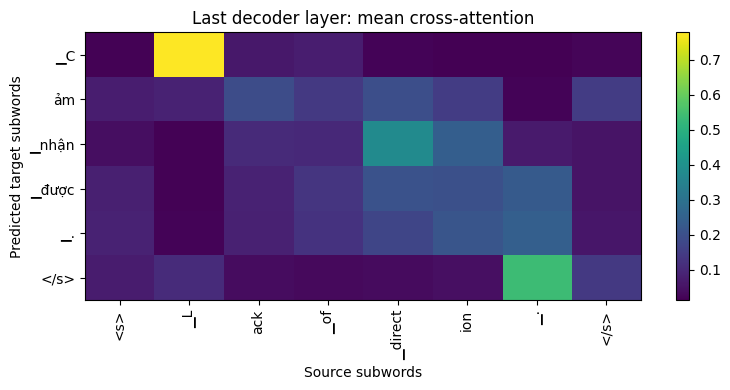

In [ ]:
columns = ["source", "reference", "prediction", "sentence_chrF"]
print("3 câu có chrF cao nhất (không đại diện toàn bộ test):")
display(translation_df.nlargest(3, "sentence_chrF")[columns])
print("3 câu có chrF thấp nhất:")
display(translation_df.nsmallest(3, "sentence_chrF")[columns])

manual_review = translation_df.head(20)[columns].copy()
manual_review["adequacy_1_to_5"] = ""
manual_review["fluency_1_to_5"] = ""
manual_review["error_notes"] = ""
manual_review.to_csv(OUTPUT_DIR / "manual_review.csv", index=False, encoding="utf-8-sig")

# Câu nguồn ngắn nhất trong 20 câu đầu; không chọn theo điểm dịch.
attention_index = test_df.head(20)["source_ids"].map(len).idxmin()
source_ids = test_df.loc[attention_index, "source_ids"]
target_ids = generated_ids[attention_index]
if EOS in target_ids:
    target_ids = target_ids[:target_ids.index(EOS) + 1]
source_tensor = tf.constant([source_ids], tf.int32)
decoder_tensor = tf.constant([target_ids[:-1]], tf.int32)
_ = model((source_tensor, decoder_tensor), training=False)
attention = model.decoder_blocks[-1].last_attention_scores.numpy()[0].mean(axis=0)
source_pieces = [source_sp.id_to_piece(token) for token in source_ids]
predicted_pieces = [target_sp.id_to_piece(token) for token in target_ids[1:]]
fig, axis = plt.subplots(figsize=(max(8, len(source_pieces) * 0.26),
                                  max(4, len(predicted_pieces) * 0.22)))
image = axis.imshow(attention, aspect="auto", cmap="viridis")
axis.set_xticks(range(len(source_pieces)), source_pieces, rotation=90)
axis.set_yticks(range(len(predicted_pieces)), predicted_pieces)
axis.set(xlabel="Source subwords", ylabel="Predicted target subwords",
         title="Last decoder layer: mean cross-attention")
fig.colorbar(image, ax=axis)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cross_attention.png", dpi=150)
plt.show()


## 11. Lưu kết quả và tạo báo cáo Markdown

Báo cáo ghi corpus/commit, split, số cặp thực tế, giới hạn độ dài, cấu hình, môi trường, thời gian, best epoch, điểm dịch và triệu chứng lỗi.

Nếu chất lượng kém, báo cáo vẫn ghi rõ. Cải thiện bằng nhiều dữ liệu, nhiều epoch, model lớn hơn, vocabulary phù hợp và beam search. Chọn các thay đổi trên validation, rồi đánh giá test sau khi chốt cấu hình.


In [ ]:
def selected_fingerprint(frame):
    records = frame[["doc_id", "pair_id", "source", "target"]].to_json(
        orient="records", force_ascii=False
    )
    return hashlib.sha256(records.encode("utf-8")).hexdigest()

metadata = dict(
    status="completed", completed_at=datetime.now().astimezone().isoformat(),
    dataset=dict(
        repository="https://github.com/qhungngo/EVBCorpus",
        release="EVBNews v1.0", commit=DATASET_COMMIT, archive_sha256=ARCHIVE_SHA256,
        scope="Public 1,000-document news subset, not all EVBCorpus",
    ),
    config=CFG, cleaning=cleaning_stats, length_filter=length_drops,
    actual_split_sizes={name: len(frame) for name, frame in selected.items()},
    actual_document_counts={name: int(frame["doc_id"].nunique()) for name, frame in selected.items()},
    split_fingerprints={name: selected_fingerprint(frame) for name, frame in selected.items()},
    environment=dict(
        python=sys.version, tensorflow=tf.__version__,
        sentencepiece=spm.__version__, sacrebleu=sacrebleu.__version__, sacremoses=importlib.metadata.version("sacremoses"),
        platform=platform.platform(),
        devices=[str(device) for device in tf.config.list_physical_devices()],
    ),
    training=dict(
        completed_epochs=len(history_df), best_epoch=best_epoch,
        best_validation_loss=float(history_df["val_loss"].min()),
        training_seconds=training_seconds, model_parameters=model.count_params(),
    ),
    decoding="greedy; source-only; BOS start; EOS stop",
    evaluation_text="MosesDetokenizer; case-sensitive; full references; BLEU 13a",
    evaluation=dict(
        transformer=transformer_scores, copy_source=copy_scores,
        metric_signatures=metric_signatures,
        test_teacher_forced={key: float(value) for key, value in test_teacher_forced.items()},
        inference_seconds=inference_seconds, diagnostics=diagnostics,
    ),
)
(OUTPUT_DIR / "experiment.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "model_config.json").write_text(
    json.dumps(CFG, indent=2), encoding="utf-8"
)

def markdown_table(frame):
    def escape(value):
        return str(value).replace("|", r"\|").replace("\n", " ")
    header = "| " + " | ".join(map(escape, frame.columns)) + " |"
    divider = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    rows = ["| " + " | ".join(map(escape, row)) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join([header, divider, *rows])

delta_bleu = transformer_scores["BLEU"] - copy_scores["BLEU"]
delta_chrf = transformer_scores["chrF"] - copy_scores["chrF"]
generalization_gap = float(
    history_df.loc[history_df["val_loss"].idxmin(), "val_loss"]
    - history_df.loc[history_df["val_loss"].idxmin(), "loss"]
)
split_table = pd.DataFrame(length_drops).T.reset_index().rename(columns={"index": "split"})
report = f"""# Báo cáo Transformer dịch {DIRECTION}

Thí nghiệm hoàn tất: {metadata['completed_at']}. {'Đây là QUICK_RUN phục vụ học tập.' if QUICK_RUN else 'Dùng toàn bộ phần train sau lọc của EVBNews v1.0.'}

## Dữ liệu và protocol

- Nguồn: [EVBCorpus](https://github.com/qhungngo/EVBCorpus), EVBNews v1.0 công khai gồm 1.000 tài liệu.
- Commit: {DATASET_COMMIT}; SHA-256 archive: {ARCHIVE_SHA256}.
- Đọc được {len(raw_df):,} cặp; còn {len(clean_df):,} cặp sau lọc sơ bộ và loại trùng.
- Chia theo tài liệu 80/10/10, seed={SEED}; không trùng document, câu nguồn hoặc câu đích giữa các tập.
- Tokenizer BPE chỉ học từ train_candidate; vocabulary nguồn/đích = {CFG['source_vocab_size']:,}/{CFG['target_vocab_size']:,}.
- Giữ chữ hoa/thường và dấu tiếng Việt; train giữ khoảng trắng dấu câu của corpus. Trước khi chấm điểm, nối lại dấu câu bằng MosesDetokenizer cho prediction/reference, không cắt reference.
- Chỉ giữ câu không vượt {CFG['max_source_tokens']} source / {CFG['max_target_tokens']} target subword tokens, tính cả BOS/EOS. Reference không bị cắt.
- Split tự tạo, không phải official benchmark; không đại diện toàn bộ EVBCorpus.

{markdown_table(split_table)}

Số tài liệu thực tế sau lấy mẫu/lọc: {metadata['actual_document_counts']}.

## Model và huấn luyện

Transformer encoder–decoder train từ đầu: {CFG['num_layers']} layer mỗi phía, d_model={CFG['d_model']}, {CFG['num_heads']} heads, d_ff={CFG['d_ff']}, dropout={CFG['dropout']}, {model.count_params():,} tham số.
Adam + warmup/inverse-square-root schedule, peak_lr={CFG['peak_lr']}, batch={CFG['batch_size']}; masked cross-entropy bỏ PAD.

Hoàn thành {len(history_df)} epoch, {training_seconds / 60:.2f} phút. Best epoch theo validation loss: **{best_epoch}**, val_loss={history_df['val_loss'].min():.4f}. Gap val-train loss tại best epoch: {generalization_gap:.4f}.
Test teacher-forced loss={test_teacher_forced['loss']:.4f}, token accuracy={test_teacher_forced['masked_token_accuracy']:.4f}. Accuracy này không đo chất lượng câu dịch tự sinh.

![Training curves](training_curves.png)

## Translation quality

Đánh giá {len(test_df)} cặp test bằng **greedy decoding**, chỉ nhận câu nguồn. Tổng thời gian inference {inference_seconds:.2f}s; lần dịch mẫu ở cell trước đã làm nóng tracing.

{markdown_table(score_table.round(3))}

Transformer so với copy-source: ΔBLEU={delta_bleu:+.3f}, ΔchrF={delta_chrf:+.3f}. Đây là so sánh mô tả với baseline đơn giản, không phải kiểm định ý nghĩa thống kê.

Metric signatures:

- BLEU: {metric_signatures['BLEU']}
- chrF: {metric_signatures['chrF']}
- chrF++: {metric_signatures['chrFpp']}

Câu rỗng: {diagnostics['empty_rate']:.1%}; không sinh EOS trước giới hạn: {diagnostics['no_eos_rate']:.1%}; có trigram lặp: {diagnostics['repeated_trigram_rate']:.1%}.
Độ dài trung bình: prediction={diagnostics['average_prediction_words']:.1f}, reference={diagnostics['average_reference_words']:.1f} đơn vị cách bởi khoảng trắng.

## Câu mẫu

6 câu đầu trong test đã shuffle, không chọn theo điểm:

{markdown_table(translation_df[['source', 'reference', 'prediction', 'sentence_chrF']].head(6).round(2))}

## Nhận xét và giới hạn

BLEU/chrF đo mức khớp với một reference; không chứng minh bản dịch bảo toàn nghĩa. Kiểm tra thủ công tên riêng, số, phủ định, bỏ sót và độ tự nhiên. manual_review.csv chưa được con người chấm, nên không có human adequacy/fluency score.

{'Cấu hình nhỏ và phần dữ liệu train hạn chế là nguyên nhân cần xem xét khi điểm dịch thấp.' if QUICK_RUN else 'Model học từ đầu trên tập tin tức; khả năng dịch lĩnh vực khác cần đánh giá riêng.'}
Tỉ lệ không sinh EOS và lặp trigram ở trên giúp kiểm tra việc sinh quá dài/lặp. Gap validation-train loss giúp quan sát khả năng khái quát, cần đọc cùng đường cong loss.
Chia theo bài báo và loại trùng chính xác giảm rò rỉ; bài báo gần trùng vẫn có thể tồn tại.

Cải thiện: mở rộng train, điều chỉnh epoch/model/vocabulary trên validation, thử beam search, rồi chốt cấu hình trước lần đánh giá test cuối. Không dùng test chọn checkpoint/hyperparameter.

## Môi trường và file

Python {platform.python_version()}, TensorFlow {tf.__version__}, SentencePiece {spm.__version__}, SacreBLEU {sacrebleu.__version__}.
Devices: {metadata['environment']['devices']}.

- best_transformer.weights.h5: weights của best validation checkpoint.
- source_sp.model, target_sp.model: tokenizers.
- model_config.json, experiment.json, document_splits.json: cấu hình/protocol/hash.
- training_history.csv, training_curves.png: quá trình học.
- test_translations.csv, translation_scores.csv: dự đoán và metrics.
- manual_review.csv, cross_attention.png: phân tích mẫu.
- translation_runtime.py: code inference độc lập để load model sau restart.

## Tham khảo

- [EVBCorpus](https://github.com/qhungngo/EVBCorpus)
- [TensorFlow Transformer tutorial](https://www.tensorflow.org/text/tutorials/transformer)
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
- [SentencePiece](https://github.com/google/sentencepiece)
- [SacreBLEU](https://github.com/mjpost/sacrebleu)
"""
REPORT_PATH = OUTPUT_DIR / "translation_quality_report.md"
REPORT_PATH.write_text(report, encoding="utf-8")
display(Markdown(report))
print("Report saved:", REPORT_PATH)

# Export code inference độc lập để dùng sau khi restart, không cần train lại.
import ast
runtime_header = "\"\"\"Standalone inference code exported by the EVBCorpus Transformer notebook.\"\"\"\nimport html\nimport json\nimport math\nimport re\nimport unicodedata\nfrom pathlib import Path\n\nimport numpy as np\nimport sentencepiece as spm\nimport tensorflow as tf\nfrom sacremoses import MosesDetokenizer\n\nPAD, UNK, BOS, EOS = 0, 1, 2, 3\n"
runtime_wrapper = "class TransformerTranslator:\n    \"\"\"Load weights and both tokenizers; translate without training data.\"\"\"\n    def __init__(self, model_dir):\n        self.model_dir = Path(model_dir)\n        self.cfg = json.loads((self.model_dir / \"model_config.json\").read_text(encoding=\"utf-8\"))\n        self.source_sp = spm.SentencePieceProcessor(\n            model_file=str(self.model_dir / \"source_sp.model\")\n        )\n        self.target_sp = spm.SentencePieceProcessor(\n            model_file=str(self.model_dir / \"target_sp.model\")\n        )\n        self.detokenizer = MosesDetokenizer(\n            lang=\"vi\" if self.cfg[\"direction\"] == \"en_to_vi\" else \"en\"\n        )\n        self.model = Transformer(self.cfg, name=\"loaded_evb_transformer\")\n        self.model((tf.constant([[BOS, EOS]], tf.int32),\n                    tf.constant([[BOS]], tf.int32)), training=False)\n        self.model.load_weights(self.model_dir / \"best_transformer.weights.h5\")\n        self.generate = make_greedy_decoder(self.model, self.cfg)\n\n    def translate_batch(self, texts):\n        if not texts:\n            return []\n        texts = [normalize_text(text) for text in texts]\n        ids = self.source_sp.encode(texts, out_type=int, add_bos=True, add_eos=True)\n        if any(len(row) > self.cfg[\"max_source_tokens\"] for row in ids):\n            raise ValueError(\"Câu nguồn vượt giới hạn token; hãy chia thành câu ngắn.\")\n        source_tokens = tf.constant(tf.keras.utils.pad_sequences(\n            ids, padding=\"post\", value=PAD, dtype=\"int32\"\n        ))\n        generated = self.generate(source_tokens).numpy().tolist()\n        results = []\n        for row in generated:\n            if EOS in row:\n                row = row[:row.index(EOS)]\n            row = [int(token) for token in row if token not in {PAD, BOS}]\n            results.append(normalize_text(self.detokenizer.detokenize(\n                self.target_sp.decode(row).split()\n            )))\n        return results\n\n    def translate(self, text):\n        return self.translate_batch([text])[0]\n"
runtime_components = [
    "normalize_text", "PositionalEmbedding", "EncoderBlock", "DecoderBlock",
    "Transformer", "make_greedy_decoder",
]
# Source từ lịch sử cell hỗ trợ cả các lớp định nghĩa trong notebook.
definitions = {}
for cell_source in get_ipython().history_manager.input_hist_raw:
    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in runtime_components:
            definitions[node.name] = ast.get_source_segment(cell_source, node)
missing_definitions = set(runtime_components) - set(definitions)
if missing_definitions:
    raise RuntimeError(f"Chưa chạy các cell định nghĩa: {sorted(missing_definitions)}")
runtime_source = (
    runtime_header + "\n\n"
    + "\n\n".join(definitions[name] for name in runtime_components)
    + "\n\n" + runtime_wrapper
)
(OUTPUT_DIR / "translation_runtime.py").write_text(runtime_source, encoding="utf-8")
print("Standalone inference code saved:", OUTPUT_DIR / "translation_runtime.py")


# Báo cáo Transformer dịch en_to_vi

Thí nghiệm hoàn tất: 2026-10-14T05:46:49.730749+07:00. Đây là QUICK_RUN phục vụ học tập.

## Dữ liệu và protocol

- Nguồn: [EVBCorpus](https://github.com/qhungngo/EVBCorpus), EVBNews v1.0 công khai gồm 1.000 tài liệu.
- Commit: 36bea570ea8e1cdde0f4ce7f4023c03e3b546a73; SHA-256 archive: 50bb92616c6ee32046a71ec6041c264d9d0f60a662e5c55257f3092c012301c4.
- Đọc được 45,308 cặp; còn 42,471 cặp sau lọc sơ bộ và loại trùng.
- Chia theo tài liệu 80/10/10, seed=42; không trùng document, câu nguồn hoặc câu đích giữa các tập.
- Tokenizer BPE chỉ học từ train_candidate; vocabulary nguồn/đích = 4,000/4,000.
- Giữ chữ hoa/thường và dấu tiếng Việt; train giữ khoảng trắng dấu câu của corpus. Trước khi chấm điểm, nối lại dấu câu bằng MosesDetokenizer cho prediction/reference, không cắt reference.
- Chỉ giữ câu không vượt 80 source / 80 target subword tokens, tính cả BOS/EOS. Reference không bị cắt.
- Split tự tạo, không phải official benchmark; không đại diện toàn bộ EVBCorpus.

| split | candidate_pairs | dropped_too_long | eligible_pairs | selected_pairs |
| --- | --- | --- | --- | --- |
| train | 6000 | 82 | 5918 | 5918 |
| validation | 3905 | 66 | 3839 | 400 |
| test | 4073 | 55 | 4018 | 300 |

Số tài liệu thực tế sau lấy mẫu/lọc: {'train': 782, 'validation': 84, 'test': 86}.

## Model và huấn luyện

Transformer encoder–decoder train từ đầu: 2 layer mỗi phía, d_model=96, 4 heads, d_ff=256, dropout=0.1, 1,579,424 tham số.
Adam + warmup/inverse-square-root schedule, peak_lr=0.001, batch=32; masked cross-entropy bỏ PAD.

Hoàn thành 12 epoch, 6.80 phút. Best epoch theo validation loss: **12**, val_loss=4.6665. Gap val-train loss tại best epoch: 0.9816.
Test teacher-forced loss=4.6061, token accuracy=0.2595. Accuracy này không đo chất lượng câu dịch tự sinh.

![Training curves](training_curves.png)

## Translation quality

Đánh giá 300 cặp test bằng **greedy decoding**, chỉ nhận câu nguồn. Tổng thời gian inference 9.56s; lần dịch mẫu ở cell trước đã làm nóng tracing.

| system | BLEU | chrF | chrFpp |
| --- | --- | --- | --- |
| Copy source | 0.964 | 11.906 | 10.377 |
| Transformer / greedy | 2.303 | 18.712 | 17.387 |

Transformer so với copy-source: ΔBLEU=+1.338, ΔchrF=+6.807. Đây là so sánh mô tả với baseline đơn giản, không phải kiểm định ý nghĩa thống kê.

Metric signatures:

- BLEU: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
- chrF: nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0
- chrF++: nrefs:1|case:mixed|eff:yes|nc:6|nw:2|space:no|version:2.6.0

Câu rỗng: 0.0%; không sinh EOS trước giới hạn: 0.3%; có trigram lặp: 44.7%.
Độ dài trung bình: prediction=25.2, reference=24.7 đơn vị cách bởi khoảng trắng.

## Câu mẫu

6 câu đầu trong test đã shuffle, không chọn theo điểm:

| source | reference | prediction | sentence_chrF |
| --- | --- | --- | --- |
| Earlier on Wednesday the maid 's lawyer , Jeffrey Shapiro , said that his client feared for herself and her daughter when she discovered Mr Strauss-Kahn 's identity a day after the incident on 14 May . | Vào sáng sớm thứ Tư, luật sư của người hầu phòng, tên là Jeffrey Shapiro, cho biết thân chủ của ông lo lắng cho chính mình và cô con gái cô ta khi cô ta khám phá ra danh tánh của ông Strauss-Kahn vào một ngày sau khi xảy ra sự cố vào ngày 14 tháng năm. | Trước khi công ty của hãng hàng ngày, giám đốc điều kiện này, một cuộc họp báo cáo của cô ấy nói rằng nó sẽ làm việc với cô ấy và tôi đã nói rằng việc mua sắm của cô ấy vào ngày thứ ba ngày thứ ba ngày sau khi cô ấy. | 20.06 |
| UK CPI inflation rate rises to 4.4% in July | Tỷ lệ lạm phát CPI của Vương quốc Anh tăng lên đến 4,4% vào tháng bảy | Cảm nhận được tăng trưởng kinh tế ở 5 năm 2010. | 10.65 |
| The United States and South Korea both say the negotiations should not resume until North Korea apologizes for the sinking of the South Korean warship . | Hoa Kỳ và Nam Triều Tiên đều nói rằng cuộc đàm phán không nên tiếp tục đến khi Bắc Triều Tiên đưa ra lời xin lỗi về vụ đánh chìm hạm của Nam Triều Tiên. | Trung Quốc và Việt Nam Triều Tiên đã nói rằng các nhà đầu tư nên cho phép từ chối đá của Mỹ từ chối đá này không khí thải toàn cầu thủ đô-la Mỹ ở Hoa Kỳ. | 27.21 |
| " The Nansha dispute over the sovereignty of islands and the jurisdiction of the sea is , in essence , a collusion of strategic interests and competition for natural resources , " said President Wu Shicun . | "Tranh chấp ở Nam Sa quay quanh vấn đề chủ quyền của các hòn đảo và quyền pháp lý đối với vùng biển này, về bản chất, là sự câu kết của các lợi ích chiến lược và tranh giành tài nguyên thiên nhiên", theo nhận xét của Chủ tịch Wu Shicun. | "Các nhà nghiên cứu đã được đưa ra khỏi khu vực di động và các nhà máy bay khác, và ở các nước này đã bị không phải là một số các công ty này, theo dõi tình trạng thái của họ sẽ làm việc làm việc làm việc làm cho biết. | 16.67 |
| Lack of direction . | Thiếu phương hướng. | Cảm nhận được. | 5.21 |
| Some are trained to bark and alert the parents when a child is having a seizure outside or in another room . | Một số được huấn luyện sủa và báo cho bố mẹ biết khi trẻ đang lên cơn co giật ở bên ngoài hoặc ở trong một phòng khác. | Một số người đàn ông ấy và bố mẹ sống thử nghiệm khi bố mẹ sống thử nghiệm trong khi người phụ nữ. | 17.96 |

## Nhận xét và giới hạn

BLEU/chrF đo mức khớp với một reference; không chứng minh bản dịch bảo toàn nghĩa. Kiểm tra thủ công tên riêng, số, phủ định, bỏ sót và độ tự nhiên. manual_review.csv chưa được con người chấm, nên không có human adequacy/fluency score.

Cấu hình nhỏ và phần dữ liệu train hạn chế là nguyên nhân cần xem xét khi điểm dịch thấp.
Tỉ lệ không sinh EOS và lặp trigram ở trên giúp kiểm tra việc sinh quá dài/lặp. Gap validation-train loss giúp quan sát khả năng khái quát, cần đọc cùng đường cong loss.
Chia theo bài báo và loại trùng chính xác giảm rò rỉ; bài báo gần trùng vẫn có thể tồn tại.

Cải thiện: mở rộng train, điều chỉnh epoch/model/vocabulary trên validation, thử beam search, rồi chốt cấu hình trước lần đánh giá test cuối. Không dùng test chọn checkpoint/hyperparameter.

## Môi trường và file

Python 3.10.6, TensorFlow 2.21.0, SentencePiece 0.2.1, SacreBLEU 2.6.0.
Devices: ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"].

- best_transformer.weights.h5: weights của best validation checkpoint.
- source_sp.model, target_sp.model: tokenizers.
- model_config.json, experiment.json, document_splits.json: cấu hình/protocol/hash.
- training_history.csv, training_curves.png: quá trình học.
- test_translations.csv, translation_scores.csv: dự đoán và metrics.
- manual_review.csv, cross_attention.png: phân tích mẫu.
- translation_runtime.py: code inference độc lập để load model sau restart.

## Tham khảo

- [EVBCorpus](https://github.com/qhungngo/EVBCorpus)
- [TensorFlow Transformer tutorial](https://www.tensorflow.org/text/tutorials/transformer)
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
- [SentencePiece](https://github.com/google/sentencepiece)
- [SacreBLEU](https://github.com/mjpost/sacrebleu)


Report saved: D:\Sudo code 2026\evb_transformer_outputs\en_to_vi_30a44431fc\translation_quality_report.md
Standalone inference code saved: D:\Sudo code 2026\evb_transformer_outputs\en_to_vi_30a44431fc\translation_runtime.py


## 12. Load lại model và dịch câu mới

Cell trước xuất file `translation_runtime.py` chứa kiến trúc và code suy luận. Giữ file này cùng `model_config.json`, hai tokenizer và weights trong một thư mục.

Sau restart, chỉ cần chạy **cell thư viện/cấu hình**, đặt `MODEL_DIR` đúng thư mục model đã lưu rồi chạy cell dưới. Không cần tải dataset hoặc train lại.

`translator.translate(text)` nhận một câu nguồn. Câu ví dụ dưới không thuộc phần chấm điểm test.



In [ ]:
# Sau restart: chạy cell thư viện/cấu hình, đặt MODEL_DIR đúng thư mục kết quả,
# rồi chạy cell này. Không cần chạy lại các cell đọc dataset/train.
MODEL_DIR = OUTPUT_DIR  # Ví dụ: Path("/content/saved_experiment")
spec = importlib.util.spec_from_file_location(
    "evb_translation_runtime", MODEL_DIR / "translation_runtime.py"
)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
translator = runtime.TransformerTranslator(MODEL_DIR)

if "model" in globals() and "batch_inputs" in globals():
    np.testing.assert_allclose(
        model(batch_inputs, training=False).numpy(),
        translator.model(batch_inputs, training=False).numpy(),
        atol=1e-5, rtol=1e-5,
    )
    print("Reload logits check passed.")
custom_sentence = (
    "Technology can improve education ."
    if translator.cfg["direction"] == "en_to_vi"
    else "Công nghệ có thể cải thiện giáo dục ."
)
print("New source:", custom_sentence)
print("Translation:", translator.translate(custom_sentence))


C:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\ops\nn.py:946: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Reload logits check passed.
New source: Technology can improve education .


Translation: Các nghiên cứu cho biết được sử dụng thuốc.
